# Heart Disease Prediction Using Healthcare Data

## Import Required Libraries

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## Load the Dataset
Load the heart disease dataset from Kaggle and display the first rows.

In [68]:
df = pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## Explore the Dataset
Examine the dataset structure, features, and basic statistics.

In [69]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nDataset Info:")
print(df.info())

print("\nStatistics:")
print(df.describe())

Shape: (1025, 14)

Columns:
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB
None

Statisti

## Check Missing Values

Verify whether the dataset contains missing values.

In [70]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

## Remove Duplicate Records

Remove duplicate rows to improve data quality.

In [71]:
df = df.drop_duplicates()

## Save Cleaned Dataset
After removing duplicates and verifying that the dataset contains no missing values, 
the cleaned dataset is saved as a new CSV file for further analysis and model training.

In [72]:
# Save the cleaned dataset
cleaned_df = df.copy()

cleaned_df.to_csv("heart_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [73]:
cleaned_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


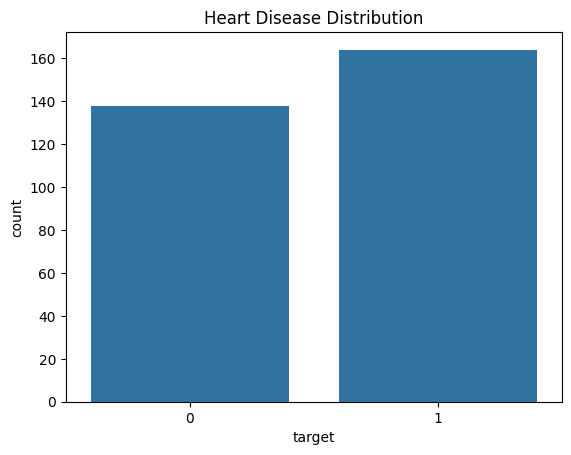

In [74]:
sns.countplot(x="target", data=df)
plt.title("Heart Disease Distribution")
plt.show()

## Age Distribution

Visualize the distribution of patient ages.

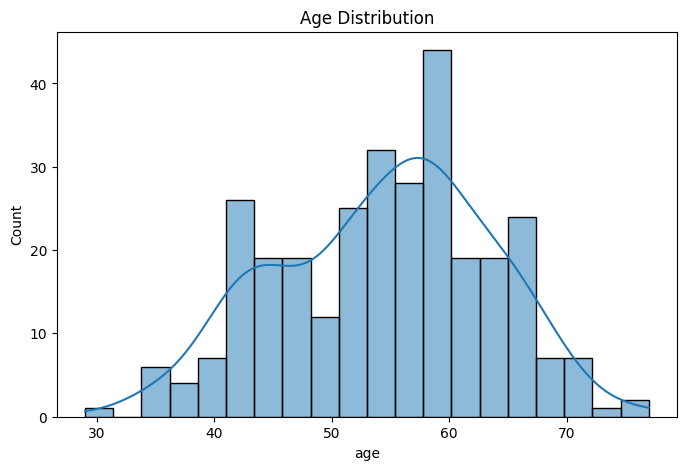

In [75]:
plt.figure(figsize=(8,5))
sns.histplot(df["age"], bins=20, kde=True)
plt.title("Age Distribution")
plt.show()

## Cholesterol Distribution

Visualize cholesterol levels among patients.

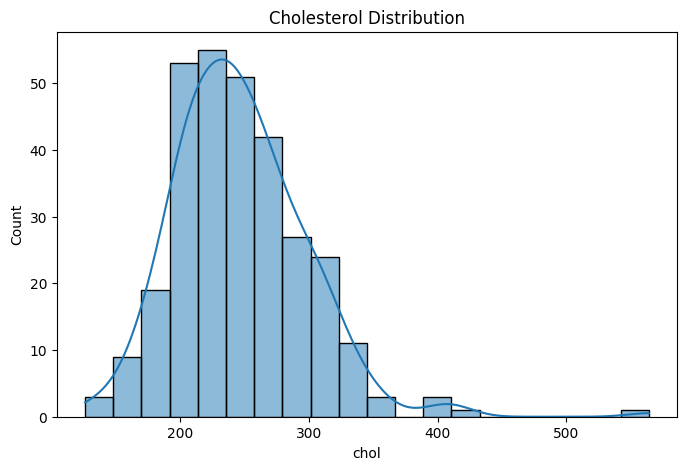

In [76]:
plt.figure(figsize=(8,5))
sns.histplot(df["chol"], bins=20, kde=True)
plt.title("Cholesterol Distribution")
plt.show()

## Outlier Detection
Detect potential outliers in numerical features to understand extreme values that may affect model performance.

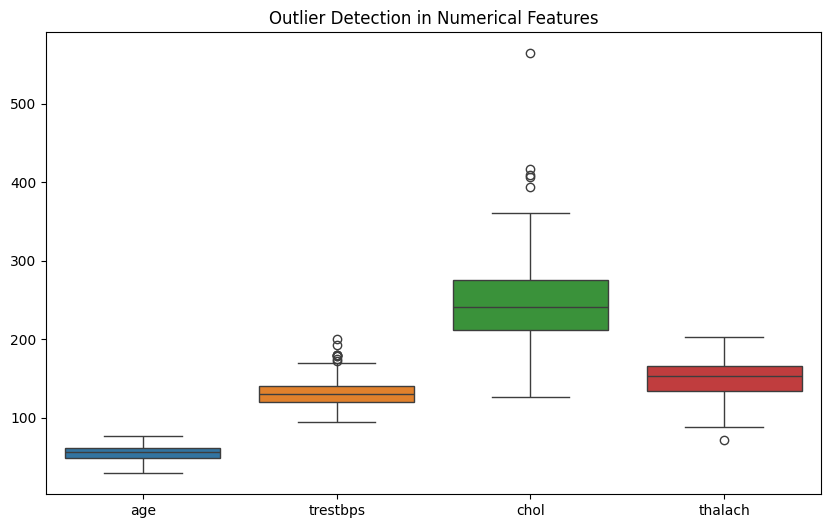

In [77]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df[["age","trestbps","chol","thalach"]])
plt.title("Outlier Detection in Numerical Features")
plt.show()

## Correlation Heatmap

Show relationships between dataset features.

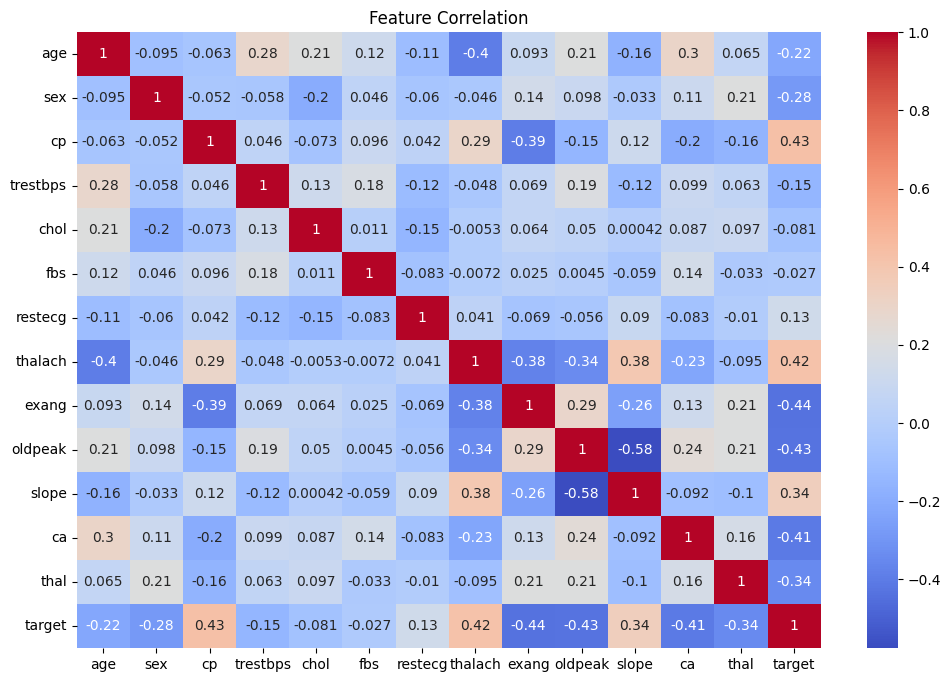

In [78]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation")
plt.show()

## Highly Correlated Features
Identify highly correlated features to detect potential multicollinearity.

In [79]:
corr_matrix = df.corr()

high_corr = corr_matrix[corr_matrix > 0.8]

high_corr

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cp,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trestbps,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chol,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fbs,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restecg,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thalach,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
exang,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
oldpeak,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN


## Chest Pain vs Heart Disease

Analyze the relationship between chest pain types and heart disease.

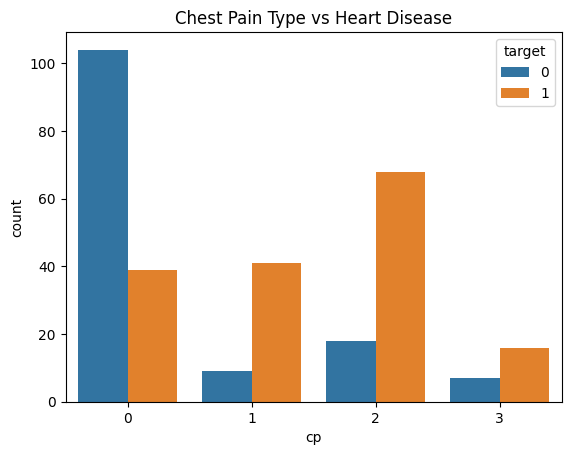

In [80]:
sns.countplot(x="cp", hue="target", data=df)
plt.title("Chest Pain Type vs Heart Disease")
plt.show()

## Gender vs Heart Disease

Analyze how heart disease cases differ between genders.

In [81]:
pd.crosstab(df["sex"], df["target"])

target,0,1
sex,,
0,24,72
1,114,92


## Average Age by Heart Disease Status

Compare the average age of patients with and without heart disease

In [82]:
df.groupby("target")["age"].mean()

target
0    56.601449
1    52.585366
Name: age, dtype: float64

## Feature Engineering
Prepare the dataset for machine learning by selecting relevant features and separating the target variable.

In [83]:
X = df.drop("target", axis=1)
y = df["target"]

## Split the Dataset

Split the data into training and testing sets.

In [84]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Feature Scaling

Standardize feature values before training the model.

In [85]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Model Training

This step trains the Logistic Regression model using the training dataset.

In [86]:
model = LogisticRegression()

model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


## Model Coefficients
Analyze feature importance using the logistic regression coefficients.

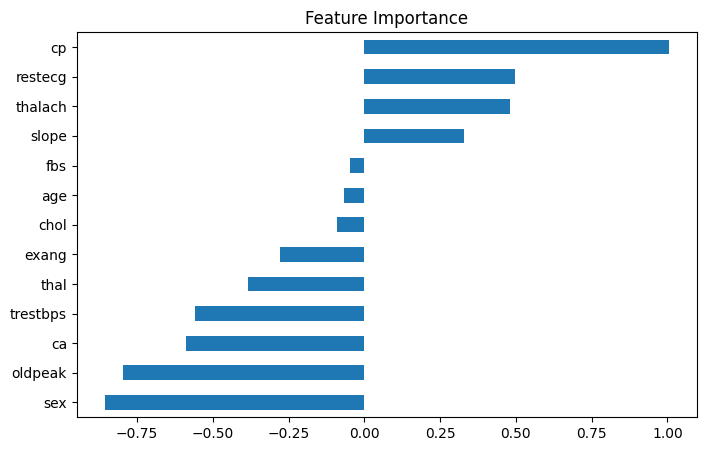

In [87]:
importance = pd.Series(model.coef_[0], index=X.columns)
importance.sort_values().plot(kind='barh', figsize=(8,5))
plt.title("Feature Importance")
plt.show()

## Make Predictions

Predict heart disease for the test dataset.

In [88]:
y_pred = model.predict(X_test)

## Model Accuracy

Evaluate the accuracy of the prediction model.

In [89]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7704918032786885


## Classification Report

Display detailed evaluation metrics of the model.

In [90]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.66      0.75        32
           1       0.70      0.90      0.79        29

    accuracy                           0.77        61
   macro avg       0.79      0.78      0.77        61
weighted avg       0.79      0.77      0.77        61



## Confusion Matrix

Visualize model prediction performance.

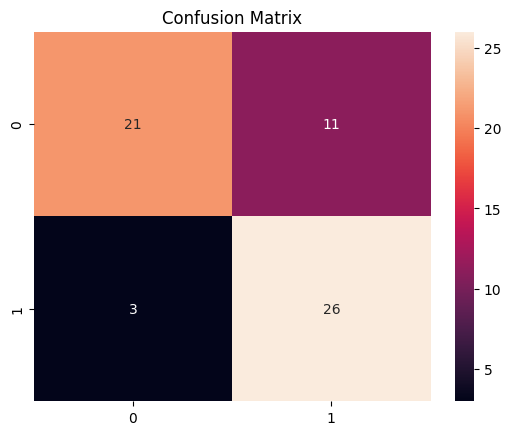

In [91]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d")
plt.title("Confusion Matrix")
plt.show()

## Predict Heart Disease for New Patient

Use the trained model to predict heart disease for new patient data.

In [92]:
new_patient = np.array([[52,1,0,125,212,0,1,168,0,1.0,2,2,3]])

new_patient = scaler.transform(new_patient)

prediction = model.predict(new_patient)

if prediction[0] == 1:
    print("Heart Disease Detected")
else:
    print("No Heart Disease")

No Heart Disease


c:\Users\wiki\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [94]:
import pandas as pd

importance = pd.Series(model.coef_[0], index=X.columns)
importance.sort_values(ascending=False)

cp          1.003914
restecg     0.495707
thalach     0.480636
slope       0.327888
fbs        -0.046923
age        -0.066593
chol       -0.089843
exang      -0.277384
thal       -0.383665
trestbps   -0.557168
ca         -0.589434
oldpeak    -0.795716
sex        -0.855829
dtype: float64